In [2]:
pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [9]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# K Means Model
from sklearn.cluster import KMeans
# Data Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import silhouette_score

In [7]:
df = pd.read_csv('Dataset/Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<Axes: >

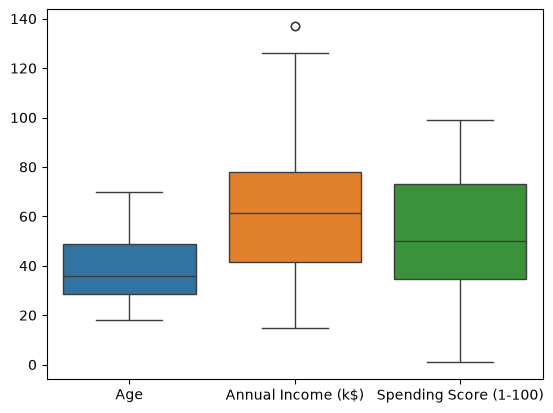

In [8]:
sns.boxplot(df[['Age', 'Annual Income (k$)','Spending Score (1-100)']])

In [ ]:

le = LabelEncoder()

In [10]:
df['GenderID'] = le.fit_transform(df['Gender'])

In [11]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),GenderID
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,0
196,197,Female,45,126,28,0
197,198,Male,32,126,74,1
198,199,Male,32,137,18,1


### Features

In [12]:
features = ['GenderID', 'Age','Annual Income (k$)','Spending Score (1-100)']
X = df[features]

### Feature Scaling

In [13]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

### eLBOW mETHOD

In [14]:
import warnings
warnings.filterwarnings("ignore")

In [15]:
k_range = range(1, 21)
error_rate =[]
for i in k_range:
    kmeans = KMeans(n_clusters=i)
    kmeans.fit_predict(X_scale)
    error_rate.append(kmeans.inertia_)

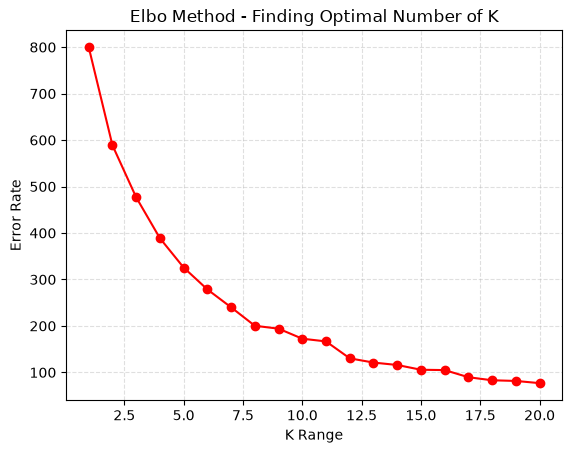

In [16]:
plt.plot(k_range, error_rate, marker = 'o', color='red')
plt.grid(linestyle='--', alpha=0.4)
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('Elbo Method - Finding Optimal Number of K')
plt.show()

### Model Implementation

In [17]:
k = 9

model = KMeans(n_clusters=k)
clusters= model.fit_predict(X_scale)
clusters

array([0, 0, 5, 8, 5, 8, 5, 8, 1, 8, 1, 8, 5, 8, 5, 0, 5, 0, 1, 8, 0, 0,
       5, 0, 5, 0, 5, 0, 5, 8, 1, 8, 1, 0, 5, 8, 5, 8, 5, 8, 2, 0, 1, 8,
       5, 8, 2, 8, 8, 8, 2, 0, 8, 1, 2, 1, 2, 1, 8, 1, 1, 0, 2, 2, 1, 0,
       2, 2, 0, 8, 1, 2, 2, 2, 1, 0, 2, 0, 8, 2, 1, 0, 1, 2, 8, 1, 2, 8,
       8, 2, 2, 0, 1, 2, 8, 0, 2, 8, 1, 0, 8, 2, 1, 0, 1, 8, 2, 1, 1, 1,
       1, 8, 2, 0, 8, 8, 2, 2, 2, 2, 0, 2, 2, 6, 8, 4, 7, 6, 1, 6, 7, 6,
       8, 4, 7, 4, 3, 6, 7, 4, 3, 6, 3, 4, 7, 6, 7, 4, 3, 6, 7, 6, 3, 4,
       3, 4, 7, 4, 7, 4, 2, 4, 7, 4, 7, 4, 7, 4, 3, 6, 7, 6, 7, 6, 3, 4,
       7, 6, 7, 6, 3, 4, 7, 4, 3, 6, 3, 6, 3, 4, 3, 4, 7, 4, 3, 4, 3, 6,
       7, 6], dtype=int32)

In [18]:
X['clusters'] = clusters

In [19]:
ss = silhouette_score(X_scale, labels=clusters)
ss

0.4044996673807779

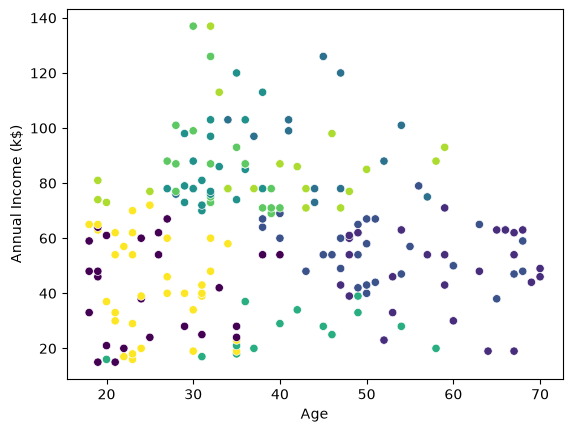

In [20]:
sns.scatterplot(data=X, x='Age', y='Annual Income (k$)', c=clusters)
plt.show()

In [21]:
import plotly.express as px

In [56]:
# px.scatter_3d(
#     X,
#     x='Age',
#     y='Annual Income (k$)',
#     z='Spending Score (1-100)',
#     color=clusters
# )

### Pair Plot

In [22]:
pair_plot =X

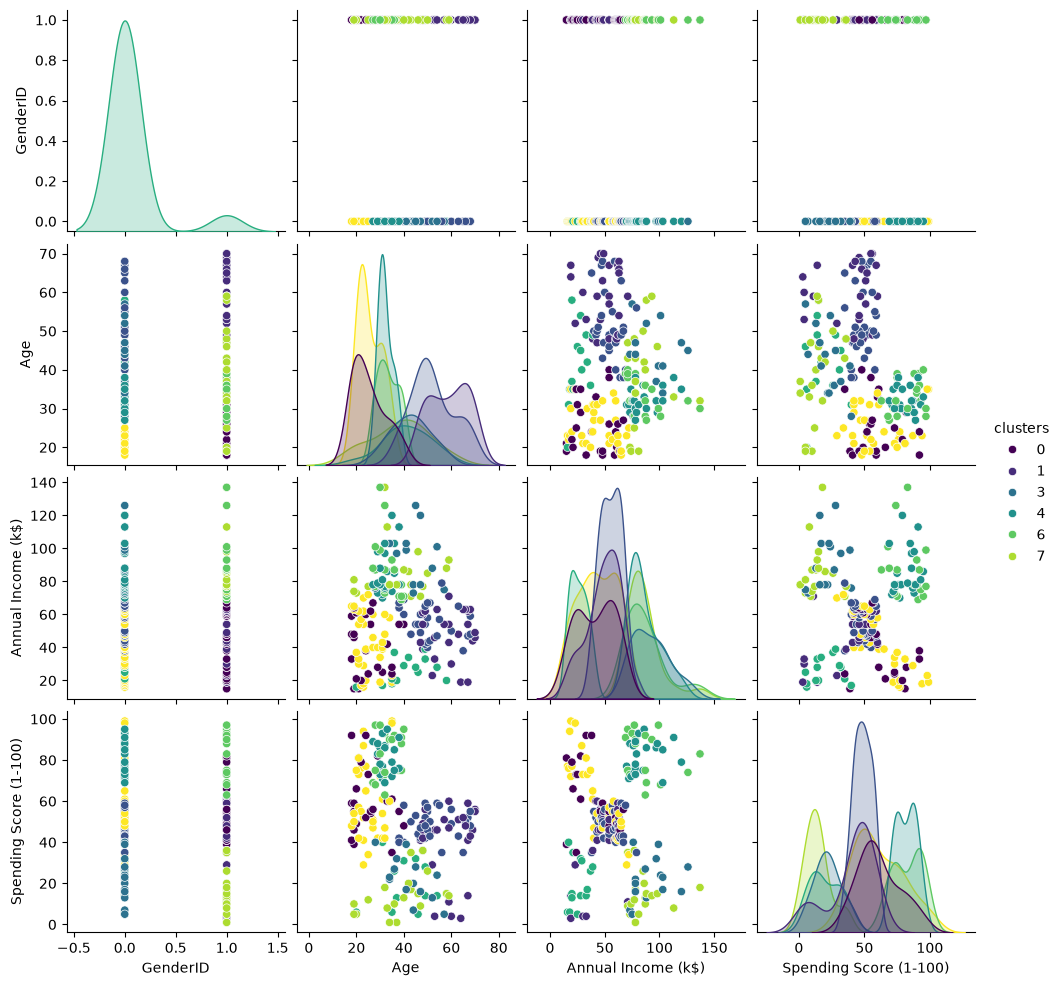

In [23]:
sns.pairplot(
    pair_plot,
    hue='clusters',
    palette='viridis'
)
plt.show()

### PCA (Principle Component Analysis)

In [24]:
from sklearn.decomposition import PCA

In [25]:
pca = PCA(n_components=len(features))

In [26]:
# Calculation of Co-Variance
pca_scale= pca.fit_transform(X_scale)
# pca_scale

In [28]:
# FInding important data for axis
loadings = pd.DataFrame(
    pca.components_,
    index=features,
    columns= [f'PC{i+1}' for i in range(len(features))]
)
loadings

,PC1,PC2,PC3,PC4
GenderID,0.234302,0.687900,-0.006082,-0.686920
Age,0.626886,-0.103690,0.765252,0.103211
Annual Income (k$),0.743009,-0.122384,-0.643667,0.136573
Spending Score (1-100),-0.007405,0.707859,0.006721,0.706283


In [29]:
'''
PC1 -> Value high -> Features -> X-axis
PC2 -> Value High -> Features -> Y-Axis

X -> Age, Annual Income(k$)
Y -> Gender, Spending Score(1-100)
'''

'\nPC1 -> Value high -> Features -> X-axis\nPC2 -> Value High -> Features -> Y-Axis\n\nX -> Age, Annual Income(k$)\nY -> Gender, Spending Score(1-100)\n'

## Visualization PCA

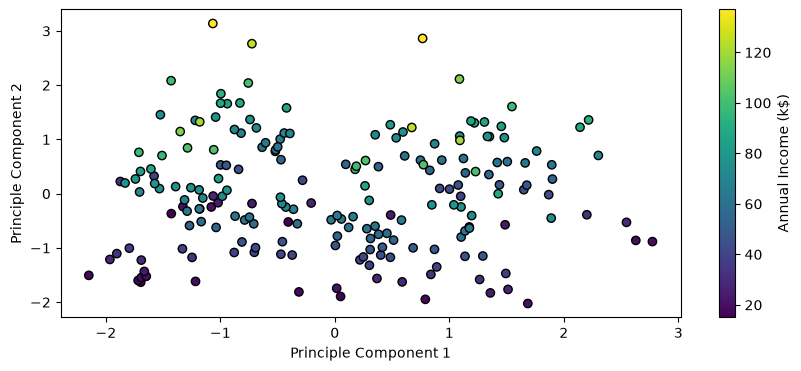

In [37]:
plt.figure(figsize=(10, 4))
color = 'Annual Income (k$)'
scatter = plt.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color], edgecolor='#000')
plt.colorbar(scatter, label=color)
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')
plt.show()

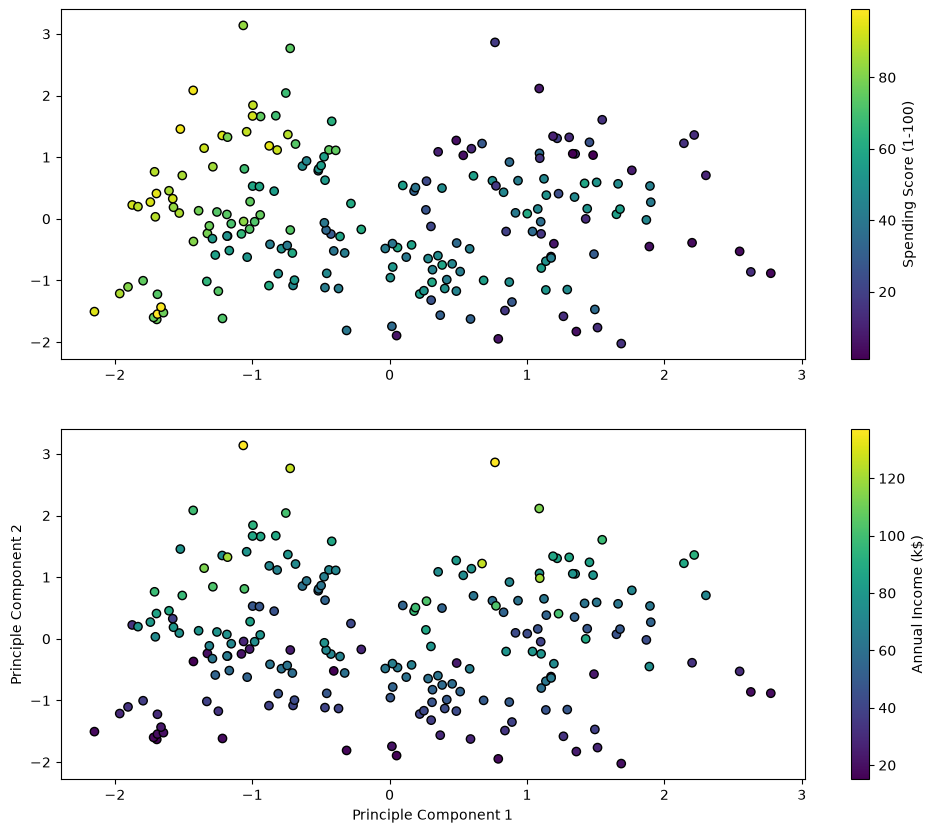

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(12,10))

ax1 = axes[0]
color1 = 'Spending Score (1-100)'
scatter = ax1.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color1], edgecolor='#000')
cbar= fig.colorbar(scatter, ax=ax1)
cbar.set_label(color1)
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')

ax2 = axes[1]
color2 = 'Annual Income (k$)'
scatter = ax2.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color2], edgecolor='#000')
cbar= fig.colorbar(scatter, ax=ax2)
cbar.set_label(color2)
plt.xlabel('Principle Component 1')
plt.ylabel('Principle Component 2')

plt.savefig('pca.png')
plt.show()